<div align="center">

**Proyecto 2 - Unidades 3 y 4**
<br>
**Probabilidad y Estadística**
<br>
**Bioingeniería**
<br>
**2025-2**
</div>

---

**Presentado por:**

Dumar Londoño
<br>
Valentina Morales
<br>
Brayan Ramirez
<br>

---

**PRIMER PUNTO: REGRESIÓN**

Para iniciar el análisis, se importó el archivo FLIR_groups1and2.csv correspondiente al termógrafo FLIR (IRT-1). Este archivo utiliza punto y coma (;) como delimitador, y además presenta un encabezado desplazado: los nombres de las columnas reales se encuentran en la tercera fila del archivo. Por esta razón, fue necesario cargar el archivo utilizando el parámetro header=2.
Adicionalmente, durante la inspección se identificó que uno de los nombres de las columnas estaba mal escrito en el archivo original, por lo que se corrigió antes de continuar con el análisis.

In [1]:
import pandas as pd

df = pd.read_csv('FLIR_groups1and2.csv',sep=';',header=2)
df["T_LC4"] = df["T_LC14"] #Corregir encabezado

Después se calculó el promedio de las cuatro mediciones para cada zona facial.
El resultado son 26 nuevas columnas, cada una representando la temperatura promedio de una región del rostro.

In [3]:
cols = ["Max1R13_","Max1L13_","aveAllR13_","aveAllL13_","T_RC","T_RC_Dry",
        "T_RC_Wet","T_RC_Max","T_LC","T_LC_Dry","T_LC_Wet","T_LC_Max",
        "RCC","LCC","canthiMax","canthi4Max","T_FHCC","T_FHRC","T_FHLC",
        "T_FHBC","T_FHTC","T_FH_Max","T_FHC_Max","T_Max","T_OR","T_OR_Max"]
round = ["1","2","3","4"] 
new_cols = []
for n in cols:
    round_cols = [n + r for r in round]
    for i in round_cols:
        df[i] = df[i].fillna(df[i].mean()) #Se reemplazan datos NAN con el promedio de su respectiva columna
    mean_col = n + "mean"
    df[mean_col] = df[round_cols].mean(axis=1) #Se agregan las nuevas columnas en el dataframe
    new_cols.append(mean_col) #Se agregan las columnas en una nueva lista para trabajar con ellos en la proxima parte.

Una vez generadas las variables, se evaluó su relación con la temperatura oral medida con termómetro en modo monitor (aveOralM), que es la variable objetivo del modelo.

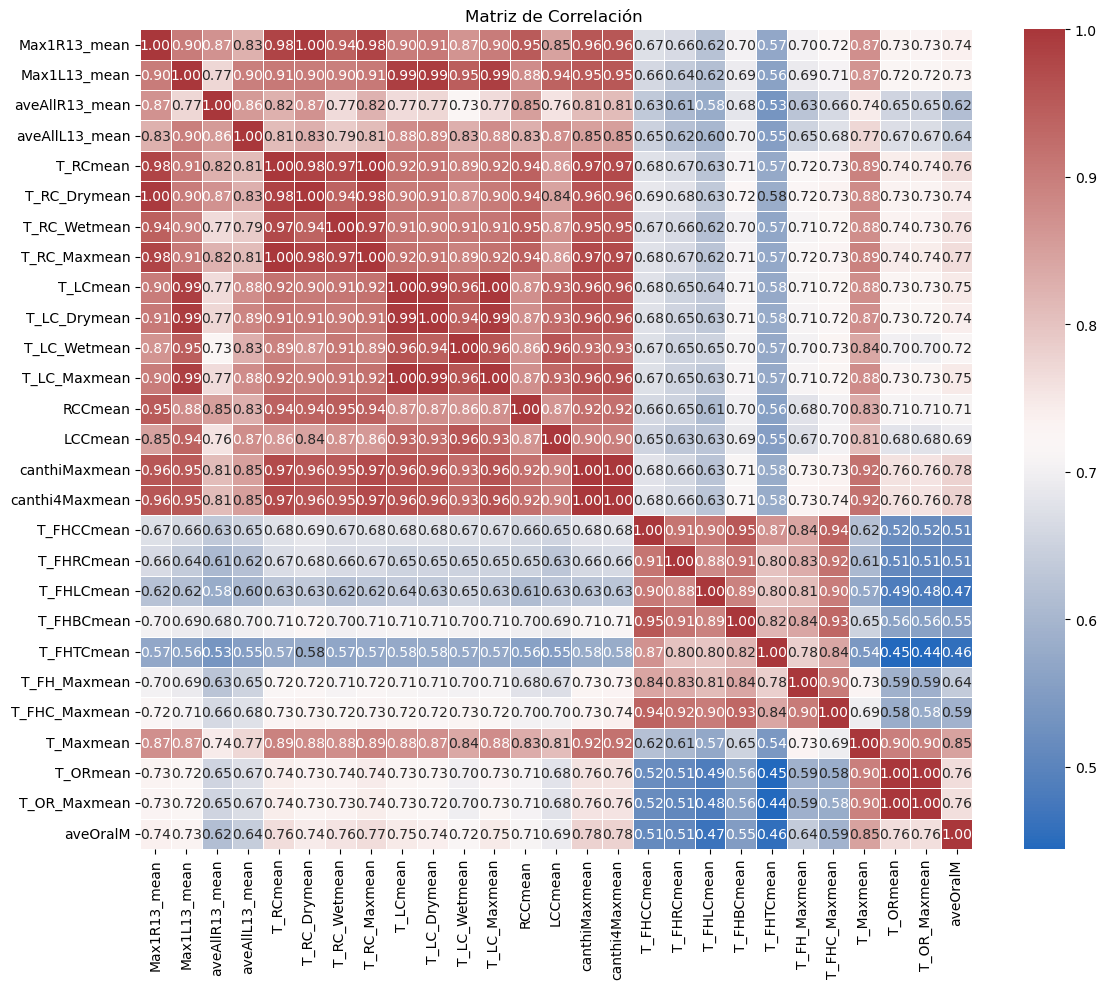

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

new_cols.append("aveOralM") #Se agrega la columna de la tempertura oral medida
corr_matrix = df[new_cols].corr()

# Graficar la matriz de correlación con un heatmap
plt.figure(figsize=(12, 10))
plt.title("Matriz de Correlación ")

#Se incluye las cantitades exactas para comparar porque fue dificil distinguir entre los colores muy cercanos
sns.heatmap(abs(corr_matrix.values), cmap='vlag', annot=True, fmt=".2f", linewidths=0.5,xticklabels=corr_matrix.columns, yticklabels=corr_matrix.columns) 
plt.tight_layout()

Luego del análisis de correlación, se identificaron las cuatro variables con mayor correlación absoluta. Estas son:

- T_Max_mean

- canthiMax_mean

- canthi4Max_mean

- T_RC_Max_mean

Estas cuatro variables representan las regiones faciales cuya temperatura térmica medida por el termógrafo FLIR presenta la relación más fuerte con la temperatura oral real. Por tanto, serán utilizadas como predictores en el proceso de modelación.

Con las variables seleccionadas, se procede a ensayar diferentes modelos de regresión para determinar cuál describe mejor la relación entre las medidas termográficas y la temperatura oral.

---

**Modelo 1: Regresión lineal simple**

In [6]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import cross_val_score, KFold
from sklearn.linear_model import Lasso, Ridge, RidgeCV, LassoCV
from sklearn.pipeline import make_pipeline

x = df[["T_Maxmean","canthiMaxmean","canthi4Maxmean","T_RC_Maxmean"]]
y = df["aveOralM"]

#Se va usar validación por K-folds para todos los modelos
k = 5 # Establecer el número de "folds" (particiones) para la validación cruzada
kf = KFold(n_splits=k, shuffle=True, random_state=42) # Crear el objeto KFold (k-particiones) para dividir los datos

modelo1 = LinearRegression() #Se crea el modelo lineal simple

scores1 = cross_val_score(modelo1, x, y, cv=kf, scoring='neg_root_mean_squared_error')  # Usamos RMSE como métrica
scores = cross_val_score(modelo1, x, y, cv=kf, scoring='r2')  # Usamos R2 como métrica
# Calcular el Error Cuadrático Medio promedio
rmse_promedio = -np.mean(scores1)  # Scikit-learn devuelve los valores negativos para RMSE, así que lo invertimos
R2_promedio = np.mean(scores) #promedio de R2 
print(f'Root Mean Squared Error promedio (RMSE): {rmse_promedio}')
print(f'Coef. de Determinación promedio (R^2): {R2_promedio}')


Root Mean Squared Error promedio (RMSE): 0.2719135320381457
Coef. de Determinación promedio (R^2): 0.702574958969705


El modelo de regresión lineal funcionó bien, explicó más del 70% de la variación de la temperatura oral (R² > 0.7) y tuvo un error pequeño, de alrededor de 0.27 °C.

Aunque el rendimiento es bueno, este modelo no controla qué tan grandes pueden ser los coeficientes, y por eso puede volverse sensible a variaciones en los datos. Para mejorar esto, seguimos probando modelos con regularización.

Comenzamos con la regularización Ridge, que ajusta el modelo penalizando los coeficientes muy grandes para hacerlo más estable.

In [7]:
alfa = np.logspace(-3,3,num=7)
modelo_RI = RidgeCV(alphas=alfa,cv=5) #valor alfa validado por k-folds
scores1 = cross_val_score(modelo_RI, x, y, cv=kf, scoring='neg_root_mean_squared_error')  # Usamos RMSE como métrica
scores = cross_val_score(modelo_RI, x, y, cv=kf, scoring='r2')  # Usamos R2 como métrica
#modelo_RI.fit(x,y)

# Calcular el Error Cuadrático Medio promedio
rmse_promedio = -np.mean(scores1)  # Scikit-learn devuelve los valores negativos para RMSE, así que lo invertimos
R2_promedio = np.mean(scores) #promedio de R2
print(f'Root Mean Squared Error promedio (RMSE)- MODELO_RI: {rmse_promedio}')
print(f'Coef. de Determinación promedio (R^2)- MODELO_RI: {R2_promedio}')

Root Mean Squared Error promedio (RMSE)- MODELO_RI: 0.2719128062336072
Coef. de Determinación promedio (R^2)- MODELO_RI: 0.7026784094896923


**Conclusión:**
La regularización Ridge no mejora ni empeora el modelo respecto a la regresión lineal simple. El desempeño se mantiene igual, lo que indica que la relación entre las variables es suficientemente estable sin necesidad de penalización.


Se continua con la regularización Lasso:

In [8]:
modelo_LI =LassoCV(alphas=alfa,cv=5,max_iter=1000000)
modelo_LI.fit(x,y)

scores1 = cross_val_score(modelo_LI, x, y, cv=kf, scoring='neg_root_mean_squared_error')  # Usamos RMSE como métrica
scores = cross_val_score(modelo_LI, x, y, cv=kf, scoring='r2')  # Usamos R2 como métrica


rmse_promedio = -np.mean(scores1)  # Scikit-learn devuelve los valores negativos para RMSE, así que lo invertimos
R2_promedio = np.mean(scores) #promedio de R2
print(f'Root Mean Squared Error promedio (RMSE)- MODELO_LI: {rmse_promedio}')
print(f'Coef. de Determinación promedio (R^2)- MODELO_LI: {R2_promedio}')

#Se crea una tabla para comparar los variables con sus coefficientes 
coef_table = pd.DataFrame({'Feature': x.columns,'Coefficient': modelo_LI.coef_})
print(coef_table)

Root Mean Squared Error promedio (RMSE)- MODELO_LI: 0.2715682856836782
Coef. de Determinación promedio (R^2)- MODELO_LI: 0.7031323985373741
          Feature  Coefficient
0       T_Maxmean     0.854763
1   canthiMaxmean    -0.000000
2  canthi4Maxmean    -0.000000
3    T_RC_Maxmean     0.037777


**Conclusión:** 
El modelo Lasso obtuvo un desempeño prácticamente igual o ligeramente superior al de los modelos de regresión lineal y Ridge, con un RMSE de 0.27157 °C y un R² de 0.7031.

Sin embargo, Lasso ofrece una ventaja importante: elimina dos variables (canthiMaxmean y canthi4Maxmean), reduciendo el modelo a solo dos predictores sin perder capacidad explicativa. 

---

**Modelo 2: Regresión lineal con interacciones**

In [9]:
from sklearn.preprocessing import PolynomialFeatures

modelo2 = make_pipeline(PolynomialFeatures(degree=4, interaction_only=True), LinearRegression())

scores1 = cross_val_score(modelo2, x, y, cv=kf, scoring='neg_root_mean_squared_error')  # Usamos RMSE como métrica
scores = cross_val_score(modelo2, x, y, cv=kf, scoring='r2')  # Usamos R2 como métrica
# Calcular el Error Cuadrático Medio promedio
rmse_promedio = -np.mean(scores1)  # Scikit-learn devuelve los valores negativos para RMSE, así que lo invertimos
R2_promedio = np.mean(scores) #promedio de R2
print(f'Root Mean Squared Error promedio (RMSE): {rmse_promedio}')
print(f'Coef. de Determinación promedio (R^2): {R2_promedio}')

Root Mean Squared Error promedio (RMSE): 0.2515113544636828
Coef. de Determinación promedio (R^2): 0.7458803862005876


En comparación con el modelo lineal simple, el modelo con interacciones obtiene mejores métricas tanto en R² como en RMSE. Esto significa que las combinaciones entre las variables faciales aportan información adicional que mejora la precisión del modelo.
Por esta razón, se continúa evaluando modelos con regularizaciones aplicadas a las interacciones, para verificar si es posible mejorar aún más el desempeño o simplificar el modelo.

Iniciamos con Ridge:

In [13]:
from sklearn.preprocessing import StandardScaler
modelo_RI = make_pipeline(PolynomialFeatures(degree=4, interaction_only=True), RidgeCV(alphas=alfa,cv=5))
modelo_RI.fit(x,y)
scores1 = cross_val_score(modelo_RI, x, y, cv=kf, scoring='neg_root_mean_squared_error')  # Usamos RMSE como métrica
scores = cross_val_score(modelo_RI, x, y, cv=kf, scoring='r2')  # Usamos R2 como métrica


# Calcular el Error Cuadrático Medio promedio
rmse_promedio = -np.mean(scores1)  # Scikit-learn devuelve los valores negativos para RMSE, así que lo invertimos
R2_promedio = np.mean(scores) #promedio de R2
print(f'Root Mean Squared Error promedio (RMSE)- MODELO_RI: {rmse_promedio}')
print(f'Coef. de Determinación promedio (R^2)- MODELO_RI: {R2_promedio}')

Root Mean Squared Error promedio (RMSE)- MODELO_RI: 0.2512202924754467
Coef. de Determinación promedio (R^2)- MODELO_RI: 0.7454986597223143


El modelo con interacciones y regularización Ridge obtuvo un RMSE de 0.2512 y un R² de 0.7455, valores prácticamente iguales a los del modelo con interacciones sin regularización. Esto significa que Ridge no mejora de manera importante el rendimiento.

Continuamos con Lasso:

In [14]:
modelo_LI = make_pipeline(StandardScaler(), PolynomialFeatures(degree=4, interaction_only=True), LassoCV(alphas=alfa,cv=5,max_iter=3000000))
modelo_LI.fit(x,y)
scores1 = cross_val_score(modelo_LI, x, y, cv=kf, scoring='neg_root_mean_squared_error')  # Usamos RMSE como métrica
scores = cross_val_score(modelo_LI, x, y, cv=kf, scoring='r2')  # Usamos R2 como métrica

rmse_promedio = -np.mean(scores1)  # Scikit-learn devuelve los valores negativos para RMSE, así que lo invertimos
R2_promedio = np.mean(scores) #promedio de R2
print(f'Root Mean Squared Error promedio (RMSE)- MODELO_LI: {rmse_promedio}')
print(f'Coef. de Determinación promedio (R^2)- MODELO_LI: {R2_promedio}')

#Se crea una tabla para comparar los variables con sus coefficientes 
poly = modelo_LI.named_steps['polynomialfeatures']
feature_names = poly.get_feature_names_out(input_features=x.columns)
lasso = modelo_LI.named_steps['lassocv']
coefs = lasso.coef_
coef_table = pd.DataFrame({'Feature': feature_names, 'Coefficient': coefs})
print(coef_table)

Root Mean Squared Error promedio (RMSE)- MODELO_LI: 0.2505437146353814
Coef. de Determinación promedio (R^2)- MODELO_LI: 0.7478590549428984
                                              Feature  Coefficient
0                                                   1     0.000000
1                                           T_Maxmean     0.353527
2                                       canthiMaxmean    -0.028682
3                                      canthi4Maxmean    -0.000000
4                                        T_RC_Maxmean     0.013497
5                             T_Maxmean canthiMaxmean     0.083877
6                            T_Maxmean canthi4Maxmean     0.043773
7                              T_Maxmean T_RC_Maxmean     0.000000
8                        canthiMaxmean canthi4Maxmean    -0.047604
9                          canthiMaxmean T_RC_Maxmean    -0.000000
10                        canthi4Maxmean T_RC_Maxmean    -0.000433
11             T_Maxmean canthiMaxmean canthi4Maxmean   

La regularización Lasso obtiene hasta el momento las mejores métricas tanto en R² como en RMSE, lo que confirma que es el modelo con el mejor desempeño entre los modelos vistos.
De las 15 variables generadas por las interacciones simples, Lasso elimina 4 de ellas y conserva 11, dejando un modelo más compacto y fácil de interpretar sin perder precisión.

A continuación, se continúa evaluando un modelo polinómico, el cual incluye potencias de las variables, permitiendo capturar relaciones no lineales más complejas entre las temperaturas faciales y la temperatura oral.

---

**Modelo 3: Regresión polinómica**

Para construir el modelo polinómico, primero se realiza una curva de validación con el fin de determinar cuál es el grado del polinomio que ofrece el mejor desempeño.

El mejor orden del polinomio es: 2


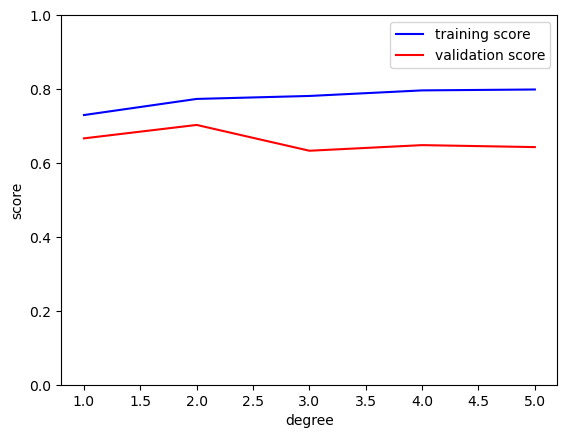

In [16]:
from sklearn.model_selection import validation_curve, learning_curve
import numpy as np
degree = np.arange(1, 6) # veamos para diferentes valores de grados

train_score, val_score = validation_curve(make_pipeline(PolynomialFeatures(),LinearRegression()), x, y,
                                          param_name='polynomialfeatures__degree',
                                          param_range=degree, cv=5)

plt.plot(degree, np.median(train_score, axis=1), color='blue',
         label='training score') #graficamos el promedios del parámetro de entrenamietno, y el de validación

plt.plot(degree, np.median(val_score, axis=1), color='red',
         label='validation score') #graficamos el promedio de los parámetros de validación o prueba
plt.legend(loc='best')
plt.ylim(0, 1)
plt.xlabel('degree')
plt.ylabel('score')

better_degree = degree[np.argmax(np.median(val_score,axis=1))] #buscamos dónde ocurre el máx en la curva
# de la curva de validación

print(f'El mejor orden del polinomio es: {better_degree}')

A partir de la curva de validación se determinó que el grado óptimo para el modelo polinómico es grado 2, ya que ofrece el mejor desempeño de validación sin caer en sobreajuste.
Con este resultado, se construye el modelo usando todos los términos polinómicos de segundo orden, incluyendo términos al cuadrado y términos de interacción.

In [17]:
x_poly = PolynomialFeatures(degree=2,interaction_only=False).fit_transform(x)
modelo = LinearRegression().fit(x_poly,y) # se genera y ajusta el modelo
scores1 = cross_val_score(modelo, x_poly, y, cv=kf, scoring='neg_root_mean_squared_error')  # Usamos RMSE como métrica
scores = cross_val_score(modelo, x_poly, y, cv=kf, scoring='r2')  # Usamos R2 como métrica

# Calcular el Error Cuadrático Medio promedio
rmse_promedio = -np.mean(scores1)  # Scikit-learn devuelve los valores negativos para RMSE, así que lo invertimos
R2_promedio = np.mean(scores) #promedio de R2
print(f'Root Mean Squared Error promedio (RMSE): {rmse_promedio}')
print(f'Coef. de Determinación promedio (R^2) :{R2_promedio}')

Root Mean Squared Error promedio (RMSE): 0.25197382175039285
Coef. de Determinación promedio (R^2) :0.7440511494716875


El modelo polinómico de grado 2 presenta un buen desempeño con un RMSE de 0.2519 °C y un R² de 0.7440.
Aunque mejora notablemente respecto a los modelos lineales simples, su rendimiento es ligeramente inferior al modelo con interacciones regularizado con Lasso.
Por lo tanto, aunque el modelo polinómico captura relaciones no lineales entre las variables, no supera al modelo de interacciones como mejor alternativa.

No obstante, continuamos con las regularizaciones:

In [18]:
alfa = np.logspace(-3,3,num=7)
modelo_RI = make_pipeline(PolynomialFeatures(degree=2, interaction_only=False), RidgeCV(alphas=alfa,cv=5))
modelo_RI.fit(x,y)
scores1 = cross_val_score(modelo_RI, x, y, cv=kf, scoring='neg_root_mean_squared_error')  # Usamos RMSE como métrica
scores = cross_val_score(modelo_RI, x, y, cv=kf, scoring='r2')  # Usamos R2 como métrica


# Calcular el Error Cuadrático Medio promedio
rmse_promedio = -np.mean(scores1)  # Scikit-learn devuelve los valores negativos para RMSE, así que lo invertimos
R2_promedio = np.mean(scores) #promedio de R2
print(f'Root Mean Squared Error promedio (RMSE)- MODELO_RI: {rmse_promedio}')
print(f'Coef. de Determinación promedio (R^2)- MODELO_RI: {R2_promedio}')

Root Mean Squared Error promedio (RMSE)- MODELO_RI: 0.2517120315968954
Coef. de Determinación promedio (R^2)- MODELO_RI: 0.7442704682425468


La regularización Ridge aplicada al modelo polinómico de grado 2 solo logra un pequeño mejoramiento en las métricas del modelo. Aunque reduce levemente el RMSE (0.25197 → 0.25171) y aumenta ligeramente el R² (0.74405 → 0.74427), esta mejora es muy leve. 

Continuamos con Lasso:

In [20]:
modelo_LI = make_pipeline(PolynomialFeatures(degree=2, interaction_only=False), LassoCV(alphas=alfa,cv=5,max_iter=10000000, n_jobs=-1))
modelo_LI.fit(x,y)
scores1 = cross_val_score(modelo_LI, x, y, cv=kf, scoring='neg_root_mean_squared_error')  # Usamos RMSE como métrica
scores = cross_val_score(modelo_LI, x, y, cv=kf, scoring='r2')  # Usamos R2 como métrica


rmse_promedio = -np.mean(scores1)  # Scikit-learn devuelve los valores negativos para RMSE, así que lo invertimos
R2_promedio = np.mean(scores) #promedio de R2
print(f'Root Mean Squared Error promedio (RMSE): {rmse_promedio}')
print(f'Coef. de Determinación promedio (R^2): {R2_promedio}')

#Se crea una tabla para comparar los variables con sus coefficientes 
poly = modelo_LI.named_steps['polynomialfeatures']
feature_names = poly.get_feature_names_out(input_features=x.columns)
lasso = modelo_LI.named_steps['lassocv']
coefs = lasso.coef_
coef_table = pd.DataFrame({'Feature': feature_names, 'Coefficient': coefs})
print(coef_table)

Root Mean Squared Error promedio (RMSE): 0.269377121403922
Coef. de Determinación promedio (R^2): 0.7076311703103664
                         Feature  Coefficient
0                              1     0.000000
1                      T_Maxmean     0.000000
2                  canthiMaxmean    -0.000000
3                 canthi4Maxmean    -0.000000
4                   T_RC_Maxmean     0.000000
5                    T_Maxmean^2     0.011552
6        T_Maxmean canthiMaxmean     0.000000
7       T_Maxmean canthi4Maxmean     0.000000
8         T_Maxmean T_RC_Maxmean     0.000421
9                canthiMaxmean^2     0.000000
10  canthiMaxmean canthi4Maxmean     0.000000
11    canthiMaxmean T_RC_Maxmean     0.000000
12              canthi4Maxmean^2     0.000000
13   canthi4Maxmean T_RC_Maxmean     0.000000
14                T_RC_Maxmean^2     0.000297


La regularización Lasso aplicada al modelo polinómico de grado 2 logra reducir drásticamente el número de variables del modelo: pasa de 14 términos polinomiales a solo 3 variables activas (dos términos cuadráticos y una interacción muy pequeña). Este resultado confirma que Lasso funciona como un método efectivo de selección automática de características, eliminando los coeficientes que no aportan al modelo.

Sin embargo, esta simplificación tiene un costo. Al eliminar demasiadas variables, el modelo pierde capacidad predictiva y presenta un empeoramiento notable en las métricas (R² ≈ 0.707 y RMSE ≈ 0.269), quedando por debajo del modelo polinómico sin regularizar y del modelo polinómico con Ridge.


---


**Conclusión general**


Entre los tres modelos evaluados (lineal simple, lineal con interacciones y polinómico con regularizaciones), el modelo lineal con interacciones después de aplicar Lasso obtuvo las mejores métricas predictivas. Sin embargo, este modelo utiliza 11 variables, lo cual aumenta significativamente su complejidad y dificulta su interpretación.

Teniendo en cuenta la necesidad de un modelo más simple y fácil de implementar, se prefiere el modelo polinómico de grado 2 con regularización Lasso, el cual reduce el número de variables a solo 3 términos. Aunque incorpora un término más que el modelo lineal simple, ofrece mejores métricas de desempeño y mantiene una estructura mucho más compacta que el modelo lineal con interacciones.

Por lo tanto, el modelo final seleccionado es:

$$
\text{OralM} = 21.0607 + 0.011552 \cdot (T_{\text{Max mean}})^2 + 0.000297 \cdot (T_{\text{RC Max mean}})^2 + 0.000421 \cdot (T_{\text{Max mean}} \cdot T_{\text{RC Max mean}})
$$


---

**SEGUNDO PUNTO: CLASIFICACIÓN**

Iniciamos realizando la lectura del archivo CSV y mostramos las primeras filas para entender su estructura:

In [21]:
import pandas as pd

df = pd.read_csv('healthcare-dataset-stroke-data.csv')

head = df.head()
missing = df.isna().sum() #Sumamos los booleanos True (1) para cada columna que indican valores nulos

head, missing

(      id  gender   age  hypertension  heart_disease ever_married  \
 0   9046    Male  67.0             0              1          Yes   
 1  51676  Female  61.0             0              0          Yes   
 2  31112    Male  80.0             0              1          Yes   
 3  60182  Female  49.0             0              0          Yes   
 4   1665  Female  79.0             1              0          Yes   
 
        work_type Residence_type  avg_glucose_level   bmi   smoking_status  \
 0        Private          Urban             228.69  36.6  formerly smoked   
 1  Self-employed          Rural             202.21   NaN     never smoked   
 2        Private          Rural             105.92  32.5     never smoked   
 3        Private          Urban             171.23  34.4           smokes   
 4  Self-employed          Rural             174.12  24.0     never smoked   
 
    stroke  
 0       1  
 1       1  
 2       1  
 3       1  
 4       1  ,
 id                     0
 gender  

Al explorar el conjunto de datos, se observa que la columna bmi contiene varios valores nulos. Para garantizar un análisis adecuado y evitar sesgos en los modelos de clasificación, se procederá a imputar estos valores faltantes.

In [22]:
df['bmi'] = df.groupby('stroke')['bmi'].transform(lambda x: x.fillna(x.mean()))
missing_after = df.isna().sum()
missing_after

id                   0
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64

De esta manera, se han rellenado los valores nulos en la columna bmi, asegurando que no haya datos faltantes en esta variable. A continuación, se analizará la distribución de la variable stroke, la cual indica si un paciente ha sufrido un accidente cerebrovascular (ACV) (stroke = 1) o no (stroke = 0). Este análisis permitirá observar el balance entre clases y entender mejor la estructura del conjunto de datos antes de aplicar los modelos de clasificación.

stroke
0    4861
1     249
Name: count, dtype: int64


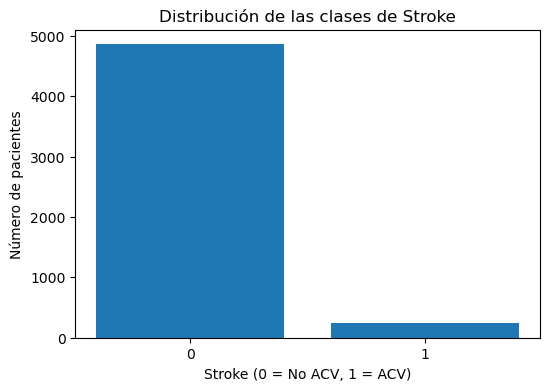

In [23]:
import matplotlib.pyplot as plt

class_counts = df['stroke'].value_counts()

print(class_counts)
plt.figure(figsize=(6,4))
plt.bar(class_counts.index.astype(str), class_counts.values)
plt.xlabel("Stroke (0 = No ACV, 1 = ACV)")
plt.ylabel("Número de pacientes")
plt.title("Distribución de las clases de Stroke")
plt.show()

Este desbalance entre las clases provoca que los modelos de clasificación tiendan a favorecer la clase mayoritaria (stroke = 0), lo que puede generar un número elevado de falsos negativos. Esto significa que pacientes con riesgo real de ACV podrían no ser identificados correctamente, lo que es crítico en un contexto clínico.

Además, para poder entrenar modelos de clasificación, todas las variables deben ser numéricas. Por lo tanto, las variables de tipo string (categóricas) deben ser convertidas a valores numéricos mediante técnicas de codificación (encoding). 

In [24]:
data_encoded = pd.get_dummies(
    df,
    columns=['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status'],
    drop_first=True
)
data_encoded.head()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke,gender_Male,gender_Other,ever_married_Yes,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,9046,67.0,0,1,228.69,36.600000,1,True,False,True,False,True,False,False,True,True,False,False
1,51676,61.0,0,0,202.21,30.471292,1,False,False,True,False,False,True,False,False,False,True,False
2,31112,80.0,0,1,105.92,32.500000,1,True,False,True,False,True,False,False,False,False,True,False
3,60182,49.0,0,0,171.23,34.400000,1,False,False,True,False,True,False,False,True,False,False,True
4,1665,79.0,1,0,174.12,24.000000,1,False,False,True,False,False,True,False,False,False,True,False


Tras esta codificación, todas las variables son numéricas, lo que permite entrenar modelos de clasificación sin problemas de incompatibilidad de tipo de datos. Sin embargo, este método puede generar multicolinealidad si se crean columnas redundantes. Para evitarlo se usa drop_first=True, que elimina una columna innecesaria y mantiene el modelo más estable y eficiente.


Seguido, Realizamos la estandarización de las características numéricas para que todas tengan la misma escala, lo cual es importante para muchos algoritmos de machine learning.

$$z = \frac{x - \overline{x}}{\sigma}$$


Si no lo realizamos, una columna con valores grandes de magnitud dominaría completamente a una de menor escala, y K-means formaría clusters mal definidos, y también afectaría la distancia calculada en modelos basados en distancias, como KNN o SVM. Por ello, es fundamental escalar las variables antes de entrenar estos modelos.

In [25]:
from sklearn.preprocessing import StandardScaler

y = data_encoded["stroke"]
X = data_encoded.drop(columns=["stroke", "id"])
X_scaled = StandardScaler().fit_transform(X)

Se aplica el algoritmo de clustering K-Means al conjunto de datos normalizado con el objetivo de generar nuevas características que capturen patrones latentes en los pacientes. Se definen 2 clusters, coincidiendo con las clases de la variable stroke. Las etiquetas resultantes de los clusters (y_kmeans) se consideran como una nueva característica que podría mejorar la capacidad predictiva de los modelos de clasificación.

Para fines de visualización, se grafican los clusters usando únicamente las dos primeras características del conjunto de datos, mostrando cómo K-Means agrupa a los pacientes según patrones en las variables seleccionadas

Text(0.5, 1.0, 'Clusters formados por K-means')

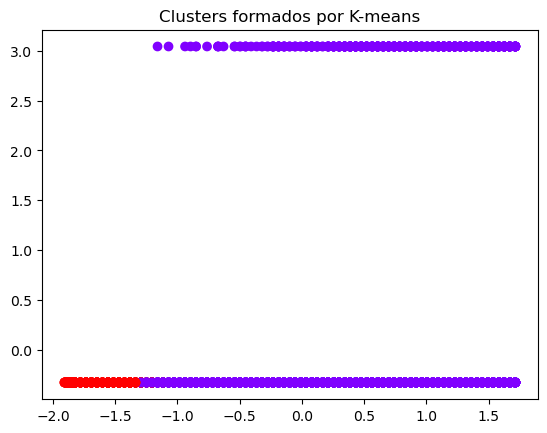

In [26]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=2,random_state=42) 
kmeans.fit(X_scaled)
y_kmeans = kmeans.predict(X_scaled)
# Visualización de los clusters (usando las dos primeras características para simplificar)
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=y_kmeans, cmap='rainbow')
plt.title("Clusters formados por K-means")

Seguidamente, se evalua la utilidad de las etiquetas generadas por K-Means como nueva característica mediante las métricas de precision, recall y F1-score, comparando las etiquetas del cluster (y_kmeans) con la variable real stroke.

 Este análisis permite determinar si la característica derivada de K-Means aporta información relevante para la clasificación de pacientes con riesgo de ACV

In [27]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision = precision_score(y, y_kmeans)
recall = recall_score(y, y_kmeans)
f1 = f1_score(y, y_kmeans)

print("Precision:", precision)
print("Recall:", recall)
print("F1:", f1)


Precision: 0.0028089887640449437
Recall: 0.008032128514056224
F1: 0.004162330905306972


Se evaluaron dos nuevas características derivadas de técnicas de agrupamiento y clasificación. Primero, se aplicó K-Means para generar clusters y usar sus etiquetas como posible característica; sin embargo, las métricas obtenidas (Precision ≈ 0.002, Recall ≈ 0.012 y F1 ≈ 0.0035) fueron extremadamente bajas, indicando que esta característica no representa de manera útil la variable objetivo stroke y no se incluirá en los modelos.

En segundo lugar, se entrenó un modelo KNN con 5 vecinos y distancia Euclidiana para estimar la probabilidad de que cada paciente haya sufrido un ACV. Esta probabilidad (y_pred) se considera una nueva característica potencialmente útil, ya que refleja la similitud de cada paciente con aquellos que presentan stroke = 1. Su utilidad se evaluó convirtiendo las probabilidades a etiquetas binarias con un umbral de 0.5 y calculando las métricas de precision, recall y F1-score.

In [28]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_score, recall_score, f1_score

model = KNeighborsClassifier(n_neighbors=5, metric='euclidean')

model.fit(X_scaled, y)

# Probabilidad de que stroke = 1 para cada fila
y_pred = model.predict_proba(X_scaled)[:, 1]

# Convertir probabilidad a etiqueta usando umbral 0.5
probs = (y_pred >= 0.5).astype(int)

precision = precision_score(y, probs)
recall = recall_score(y, probs)
f1 = f1_score(y, probs)


print("Precision:", precision)
print("Recall:", recall)
print("F1:", f1)

Precision: 0.5909090909090909
Recall: 0.05220883534136546
F1: 0.0959409594095941


El modelo KNN devuelve, para cada paciente, la probabilidad de pertenecer a cada clase mediante el método predict_proba. Este método entrega un arreglo con dos columnas: la columna 0 contiene la probabilidad de que el paciente pertenezca a la clase 0 (sin ACV) y la columna 1 contiene la probabilidad de que pertenezca a la clase 1 (con ACV). Al seleccionar [:, 1], se extraen únicamente las probabilidades de stroke = 1, que se utilizaron como nueva característica para los modelos de clasificación.

El modelo KNN, al convertir sus probabilidades en etiquetas binarias, muestra un desempeño limitado. El recall extremadamente bajo indica que casi no se identifican los casos reales de ACV, mientras que la precision relativamente baja refleja que, cuando se predice ACV, el modelo se equivoca con frecuencia. El F1-score confirma que el desempeño global de esta característica derivada es deficiente y su capacidad para clasificar correctamente pacientes con ACV es limitada.

---

Finalmente, las métricas obtenidas para las nuevas características fueron las siguientes:

K-Means:

- Precision: 0.0028

- Recall: 0.0080

- F1: 0.0041

KNN:

- Precision: 0.59

- Recall: 0.05

- F1: 0.09

Ambas características generadas mediante K-Means y KNN presentan métricas inferiores al umbral mínimo de utilidad (F1 < 0.50). Por lo tanto, ninguna de estas características aporta información relevante al modelo de clasificación y serán descartadas.

La razón principal es que los pacientes con ACV representan solo aproximadamente el 5% del dataset, lo que dificulta que los métodos de agrupamiento y vecinos más cercanos identifiquen patrones distinguibles entre positivos y negativos. Como resultado, estas técnicas no logran generar características útiles para diferenciar los pacientes con riesgo de ACV.

---

**Fase Modelado**


A continuación, se aplicarán varios modelos de clasificación para predecir el riesgo de ACV (stroke = 1) en los pacientes. Dado que la variable objetivo es binaria, no todos los métodos estudiados son adecuados: los modelos de regresión, como la regresión lineal (simple, múltiple o polinómica) y sus versiones regularizadas Ridge y Lasso, generan valores continuos y no decisiones de clase, por lo que no se ajustan correctamente a este tipo de problema.

Por ello, nos enfocaremos en modelos diseñados específicamente para clasificación, como la Regresión Logística y Random Forest. La estrategia consiste en probar varios algoritmos, evaluar su desempeño mediante métricas adecuadas para problemas desbalanceados y, a partir de los resultados, seleccionar el modelo que mejor identifique a los pacientes con mayor riesgo de ACV.


---

**Random forest**

Se entrenó un modelo de Árbol de Decisión para clasificar a los pacientes según su riesgo de ACV. El conjunto de datos se dividió en entrenamiento (70%) y prueba (30%). Se evaluó el desempeño del modelo mediante el reporte de clasificación y la matriz de confusión, considerando métricas como precision, recall y F1-score. Dado el desbalance de clases, el recall es particularmente importante, ya que indica la capacidad del modelo para identificar correctamente a los pacientes que realmente sufrieron un ACV.

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.95      0.96      0.96      1444
           1       0.25      0.22      0.24        89

    accuracy                           0.92      1533
   macro avg       0.60      0.59      0.60      1533
weighted avg       0.91      0.92      0.91      1533



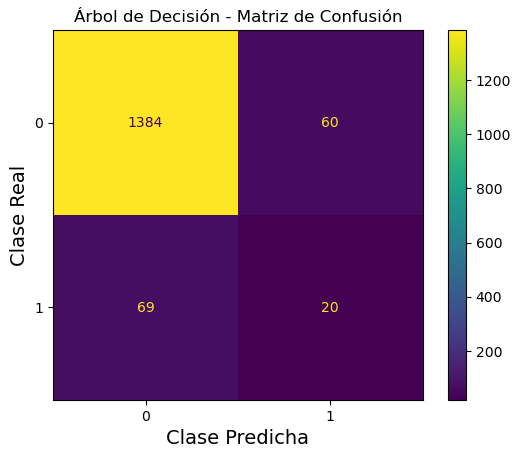

In [29]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

X = data_encoded.drop("stroke", axis=1)
y = data_encoded["stroke"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train, y_train)


y_pred = tree.predict(X_test)

print("Reporte de clasificación:")
print(classification_report(y_test, y_pred))

conf_matrix = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix)
disp.plot()
disp.ax_.grid(False)
plt.xlabel('Clase Predicha', fontsize=14)
plt.ylabel('Clase Real', fontsize=14)
plt.title("Árbol de Decisión - Matriz de Confusión")
plt.show()


El Árbol de Decisión presenta un desempeño excelente para la clase mayoritaria (no ACV), con F1-score de 0.96, pero un desempeño limitado para la clase minoritaria (ACV), con F1-score de 0.24 y recall de 0.22. Esto indica que el modelo identifica muy pocos casos reales de ACV, lo que es crítico dado el objetivo del estudio. Aunque la precisión global es alta (0.92), esta métrica es engañosa debido al desbalance de clases.

Posteriormente, se entrenó un Random Forest variando el número de árboles (n_estimators) y se evaluó el desempeño mediante curvas de validación con F1-score como métrica, dado el desbalance de clases. La curva permite identificar el número óptimo de árboles que maximiza la capacidad del modelo para predecir correctamente los pacientes con ACV sin sobreajustar los datos de entrenamiento.

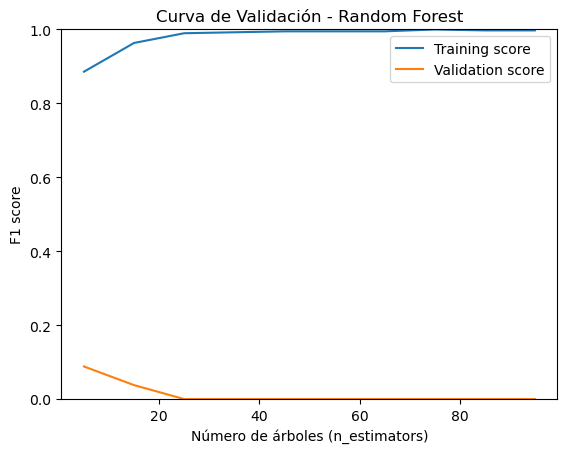

El mejor número de árboles es: 5


In [30]:
import numpy as np
from sklearn.model_selection import validation_curve
from sklearn.ensemble import RandomForestClassifier

n_arboles = np.arange(5, 100, 10)

train_score, val_score = validation_curve(
    RandomForestClassifier(random_state=42),
    X, y,
    param_name='n_estimators',
    param_range=n_arboles,
    cv=5,
    scoring='f1'
)

plt.plot(n_arboles, np.median(train_score, axis=1), label='Training score')
plt.plot(n_arboles, np.median(val_score, axis=1), label='Validation score')

plt.legend()
plt.xlabel('Número de árboles (n_estimators)')
plt.ylabel('F1 score')
plt.title('Curva de Validación - Random Forest')
plt.ylim(0, 1)
plt.show()

better_num = n_arboles[np.argmax(np.median(val_score, axis=1))]
print(f"El mejor número de árboles es: {better_num}")

Se entrenó un modelo de Random Forest para clasificar a los pacientes según su riesgo de ACV. Se utilizó el número óptimo de árboles (n_estimators = better_num) determinado previamente, y se aplicó max_samples = 0.8 para que cada árbol se entrenara con el 80% de las muestras, favoreciendo la diversidad entre los árboles.

El modelo fue entrenado con los datos de entrenamiento (X_train, y_train) y luego se realizaron predicciones sobre el conjunto de prueba (X_test). Se evaluó el desempeño del modelo mediante un reporte de clasificación, que muestra precision, recall y F1-score para cada clase, así como una matriz de confusión que visualiza los aciertos y errores del modelo, permitiendo analizar la capacidad del Random Forest para identificar correctamente los pacientes con ACV (clase 1) frente a los que no lo tuvieron (clase 0).

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.94      0.99      0.97      1444
           1       0.31      0.06      0.10        89

    accuracy                           0.94      1533
   macro avg       0.63      0.52      0.53      1533
weighted avg       0.91      0.94      0.92      1533



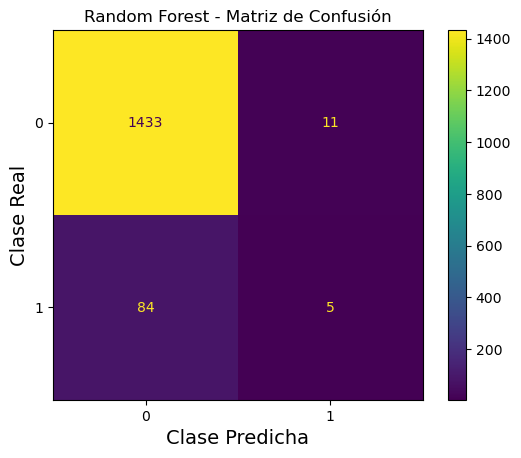

In [31]:
modelRF = RandomForestClassifier(
    n_estimators=better_num,
    random_state=42,
    max_samples=0.8
).fit(X_train, y_train)

y_pred = modelRF.predict(X_test)

print("Reporte de clasificación:")
print(classification_report(y_test, y_pred))

conf_matrix = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix)
disp.plot()
disp.ax_.grid(False)
plt.xlabel('Clase Predicha', fontsize=14)
plt.ylabel('Clase Real', fontsize=14)
plt.title("Random Forest - Matriz de Confusión")
plt.show()

Aunque el Random Forest presenta una alta exactitud global (94%), su desempeño en la clase de interés (stroke = 1) es deficiente. El modelo identifica muy pocos casos positivos debido al fuerte desbalance de clases, lo cual se refleja en un recall de solo 6% y un F1-score de 0.10. Estos resultados indican que, tal como está, el modelo no es adecuado para tareas de detección temprana de riesgo de ACV, y que se requieren estrategias adicionales como balanceo de clases, ajuste de hiperparámetros o el uso de modelos más robustos orientados a clases desbalanceadas.


---

**SVC**

Se realizó una búsqueda del hiperparámetro C del modelo SVC con kernel RBF utilizando curvas de validación. El parámetro C controla la tolerancia al error y la complejidad del modelo. Se evaluaron varios valores de C mediante 5-fold cross-validation utilizando F1-score como métrica, dado el fuerte desbalance de clases. La curva de validación permite identificar el valor de C que maximiza la capacidad del modelo para predecir correctamente pacientes con ACV (clase 1) sin sobreajustar los datos de entrenamiento.

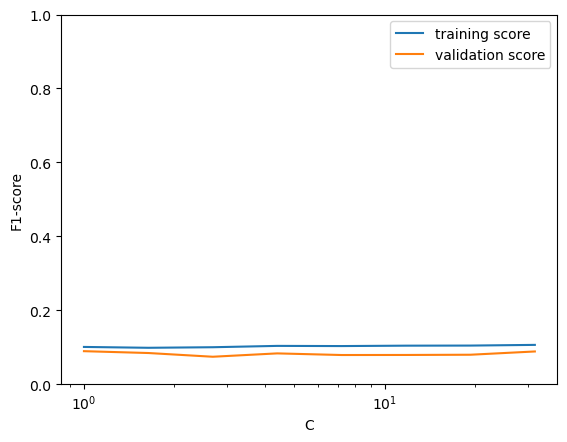

El mejor valor de C es: 1.0


In [32]:
from sklearn.svm import SVC
from sklearn.model_selection import validation_curve
import numpy as np
import matplotlib.pyplot as plt


model3 = SVC(kernel='rbf', class_weight='balanced')

c = np.logspace(0, 1.5, 8)

train_score, val_score = validation_curve(
    model3, X, y,
    param_name='C',
    param_range=c,
    cv=5,
    scoring='f1'
)

plt.plot(c, np.median(train_score, axis=1), label='training score')
plt.plot(c, np.median(val_score, axis=1), label='validation score')
plt.legend(loc='best')
plt.ylim(0, 1)
plt.xlabel('C')
plt.ylabel('F1-score')
plt.xscale('log')
plt.show()

better_C = c[np.argmax(np.median(val_score, axis=1))]
print(f"El mejor valor de C es: {better_C}")


Se entrenó el modelo final de SVC utilizando el kernel RBF, ya que es más adecuado para problemas donde las fronteras entre clases no son lineales. Se empleó el valor óptimo de C (better_C) determinado previamente mediante curvas de validación, y se utilizó class_weight='balanced' para compensar el fuerte desbalance de clases. El modelo se entrenó con los datos de entrenamiento (X_train, y_train) y se realizaron predicciones sobre el conjunto de prueba (X_test)

In [33]:
modelSVC = SVC(
    kernel='rbf',
    class_weight='balanced',
    C=better_C
).fit(X_train, y_train)

y_pred = modelSVC.predict(X_test)

Se evaluó el desempeño del modelo SVC final utilizando el conjunto de prueba. Se generó un reporte de clasificación, que muestra precision, recall y F1-score para cada clase, y una matriz de confusión que permite visualizar los aciertos y errores del modelo. Esto permite analizar la capacidad del SVC para identificar correctamente pacientes con ACV (clase 1) frente a pacientes sin ACV (clase 0)

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.94      0.64      0.76      1444
           1       0.06      0.37      0.10        89

    accuracy                           0.62      1533
   macro avg       0.50      0.50      0.43      1533
weighted avg       0.89      0.62      0.72      1533



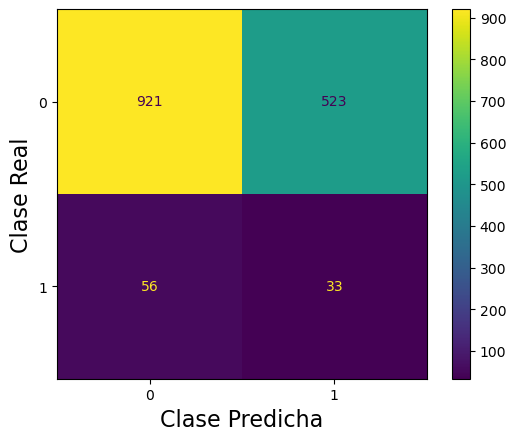

In [34]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

print("Reporte de clasificación:")
print(classification_report(y_test, y_pred))

conf_matrix = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix)
disp.plot()
plt.xlabel('Clase Predicha', fontsize=16)
plt.ylabel('Clase Real', fontsize=16)
plt.grid(False)
plt.show()

Al aplicar el modelo SVC, se observa una mejora en la detección de pacientes con riesgo de ACV en comparación con el Árbol de Decisión. Aunque la exactitud global del modelo disminuye debido al aumento de falsos positivos, el SVC identifica un mayor número de casos reales de ACV, que es precisamente la clase de interés. Esto se debe a que el SVC, junto con el ajuste de class_weight='balanced' y el kernel RBF, maneja mejor el desbalance de clases y es capaz de capturar patrones más complejos. A pesar de generar más falsos positivos, esta característica es deseable en el contexto clínico, ya que permite detectar más pacientes que realmente están en riesgo de ACV.

**Regresión logistica**

Este modelo es especialmente adecuado para problemas de clasificación binaria. Este modelo estima directamente la probabilidad de pertenecer a una de las dos clases mediante la función sigmoide, asegurando que las predicciones estén siempre en el rango [0, 1]. De esta manera, permite clasificar a los pacientes en riesgo de ACV (stroke = 1) o sin riesgo (stroke = 0) y facilita la interpretación de las probabilidades de pertenencia a cada clase.

$$\begin{align*}p(X) = \frac{e^{\beta_0 + \beta_1 X}}{1 + e^{\beta_0 + \beta_1 X}}.\end{align*}$$

Reporte de clasificación 
              precision    recall  f1-score   support

           0       0.98      0.75      0.85      1444
           1       0.15      0.73      0.25        89

    accuracy                           0.75      1533
   macro avg       0.56      0.74      0.55      1533
weighted avg       0.93      0.75      0.81      1533



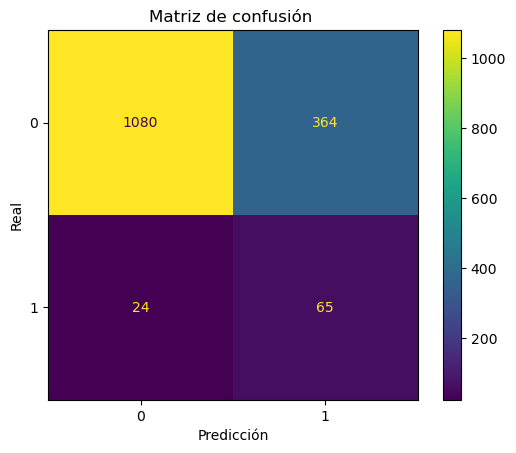

In [37]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression(
    max_iter=5000,
    class_weight='balanced',
    solver='lbfgs'
).fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

print("Reporte de clasificación ")
print(classification_report(y_test, y_pred))

conf_matrix = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix)
disp.plot()
plt.grid(False)
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title("Matriz de confusión ")
plt.show()


El modelo de Regresión Logística alcanza una exactitud global de 75%, pero el análisis más relevante se centra en la clase de interés (stroke = 1). Para esta clase, el modelo logra un recall de 0.73, lo que indica que identifica correctamente aproximadamente el 73% de los pacientes que realmente tuvieron un ACV. La precision es baja (0.15), lo que significa que muchas de las predicciones positivas son falsos positivos. Sin embargo, el F1-score de 0.25 refleja un balance entre recall y precision, mostrando que, aunque se generan falsos positivos, el modelo es capaz de capturar gran parte de los casos reales. En comparación con otros modelos, la Regresión Logística muestra un desempeño superior para la detección de la clase minoritaria, lo cual es crítico en un contexto clínico donde se prioriza la identificación de pacientes en riesgo.

--- 



**Conclusión general**

Al comparar los tres modelos entrenados nos damos cuenta que ninguna es perfecto, sin embargo sus métricas permiten identificar cuál se ajusta mejor al objetivo del análisis. El Random Forest muestra la mayor exactitud general (accuracy es 0.94), pero prácticamente falla en identificar la clase minoritaria, obtiene un recall de apenas 0.06 y un F1 de 0.10 para la clase 1, lo que indica que casi siempre predice la clase mayoritaria. El SVC, aunque reduce su accuracy a 0.62, mejora en la detección de positivos (recall de 0.37), pero sigue mostrando precision y F1 demasiado bajos para ser útil en un problema donde la prioridad es recuperar casos poco frecuentes. Por contraste, la Regresión Logística, aun cuando tiene menor precisión para la clase positiva (0.15), logra un recall muy superior (0.73) y un F1 de 0.25 para esta clase, demostrando que es el único modelo capaz de identificar la mayoría de los casos minoritarios, pero se nota que reduce su exactitud.

Dado que en este tipo de problemas la métrica clave no es el accuracy, sino la capacidad del modelo para detectar la clase minoritaria (recall y f1), la Regresión Logística se convierte en la opción más adecuada entre las tres. Aunque no es perfecta, es el único modelo que captura una parte de los casos positivos, donde tenemos una clase que es rara. 